## 1. Setup (Colab / Kaggle / local / Vast.ai)

In [1]:
import os
import re
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/oelaimar/NeuroVision-AI.git"
DATA_FILE_ID = "1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs"
DATA_SHA256 = None

# Already provided by Colab/Kaggle: don't reinstall (keeps their CUDA-matched builds)
SKIP = {"numpy", "pandas", "scipy", "matplotlib", "scikit-learn", "pillow",
        "torch", "torchvision", "tensorflow", "opencv-python"}

def sh(*cmd):
    subprocess.check_call(cmd)

if Path("/kaggle/working").exists():
    base_dir = Path("/kaggle/working")
elif Path("/content").exists():
    base_dir = Path("/content")
else:
    base_dir = None  # local / Vast.ai: notebook runs inside the cloned repo

if base_dir:
    root = base_dir / "NeuroVision-AI"
    if not root.exists():
        sh("git", "clone", REPO_URL, str(root))
    sh("git", "-C", str(root), "checkout")

    reqs = []
    for line in (root / "requirements.txt").read_text().splitlines():
        line = line.strip()
        if not line or line.startswith(("#", "-")):
            continue
        name = re.split(r"[<>=!~\[;\s]", line, maxsplit=1)[0].lower().replace("_", "-")
        if name not in SKIP:
            reqs.append(line)
    if reqs:
        sh(sys.executable, "-m", "pip", "install", *reqs)
else:
    root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

os.chdir(root)
sys.path.insert(0, str(root))
print("Repo:", root, "| commit:",
      subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip())

fatal: not a git repository (or any of the parent directories): .git


CalledProcessError: Command '['git', 'rev-parse', '--short', 'HEAD']' returned non-zero exit status 128.

## 2. Imports, config, dataset

In [3]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src.balance import class_distribution
from src.config import Config
from src.dataset_download import ensure_dataset
from src.pipeline import DataSpec, build_augmenter, get_datasets, get_splits, get_test_ds
from src.repro import set_seed, start_run

cfg = Config()
set_seed(cfg)

RAW_DIR = cfg.data_dir
CLASSES = list(cfg.classes)
IMG_SIZE = cfg.img_size
BATCH_SIZE = cfg.batch_size

ensure_dataset(RAW_DIR, CLASSES, DATA_FILE_ID, DATA_SHA256)

spec = DataSpec(
    raw_dir=cfg.data_dir,
    classes=cfg.classes,
    val_split=cfg.val_frac,
    test_split=cfg.test_frac,
    target_size=cfg.img_size,
    cache_path=cfg.cache_path,
    manifest_path=cfg.manifest_path,
    seed=cfg.seed,
)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))


2026-10-21 12:24:57.543401: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792585497.562243    1014 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792585497.568120    1014 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792585497.583446    1014 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792585497.583460    1014 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792585497.583462    1014 computation_placer.cc:177] computation placer alr

ModuleNotFoundError: No module named 'src'

## 3. Check that every file is an image

In [2]:
IMG_EXT = {".jpg", ".jpeg", ".png"}
non_image = [
    p for c in CLASSES for p in (Path(RAW_DIR) / c).rglob("*")
    if p.is_file() and p.suffix.lower() not in IMG_EXT
]
print(len(non_image))

NameError: name 'CLASSES' is not defined

## 4. Load data and class balance

Duplicates removed: 426 (kept 6597)

Class distribution (full dataset, after dedup)
  glioma         1620   24.6%  #####################################
  meningioma     1531   23.2%  ###################################
  notumor        1706   25.9%  #######################################
  pituitary      1740   26.4%  ########################################
  imbalance ratio (max/min) = 1.14 -> balanced enough: no rebalancing needed


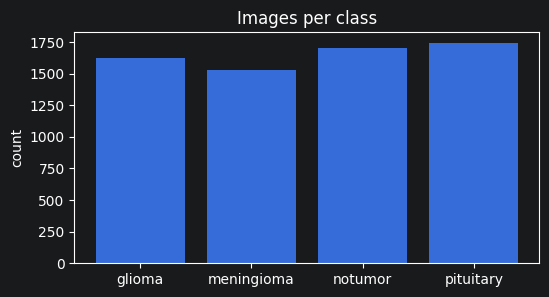

In [8]:
(X_tr, y_tr), (X_va, y_va), (_, y_te) = get_splits(spec)
counts = class_distribution(np.concatenate([y_tr, y_va, y_te]), CLASSES, "(full dataset, after dedup)")

plt.figure(figsize=(6, 3))
plt.bar(CLASSES, counts)
plt.title("Images per class")
plt.ylabel("count")
plt.show()

## 5. tf.data pipelines and run record

In [9]:
train_ds, val_ds, class_weight = get_datasets(spec, BATCH_SIZE, strategy=cfg.strategy)
run_dir = start_run(cfg, spec, name="mobilenetv2")
print("Run dir:", run_dir)


Class distribution (train)
  glioma         1134   24.5%  #####################################
  meningioma     1073   23.2%  ###################################
  notumor        1196   25.9%  #######################################
  pituitary      1218   26.4%  ########################################
  imbalance ratio (max/min) = 1.14 -> balanced enough: no rebalancing needed

Class distribution (val)
  glioma          243   24.6%  #####################################
  meningioma      229   23.2%  ###################################
  notumor         255   25.8%  #######################################
  pituitary       261   26.4%  ########################################
  imbalance ratio (max/min) = 1.14 -> balanced enough: no rebalancing needed

Class distribution (test, counts only)
  glioma          243   24.6%  #####################################
  meningioma      229   23.2%  ###################################
  notumor         255   25.8%  ###########################

I0000 00:00:1792583367.469934    3833 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 10260 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:88:00.0, compute capability: 8.6


Run dir: runs/20261021-114929_mobilenetv2_seed42


## 6. Sanity checks

In [10]:
for xb, yb in train_ds.take(1):
    print(xb.shape, xb.dtype, yb.shape)
    print("pixel range:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))

2026-10-21 11:49:35.336553: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_19}}


(32, 224, 224, 3) <dtype: 'float32'> (32,)
pixel range: 0.0 - 1.0


2026-10-21 11:49:35.872848: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


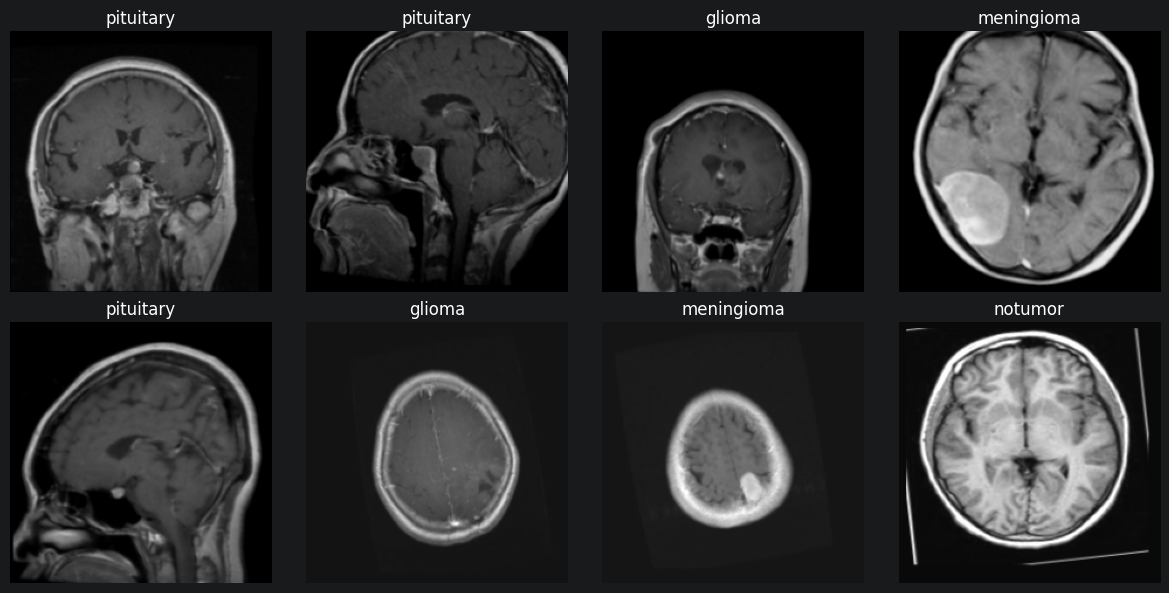

In [11]:
xb, yb = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(xb[i].numpy()[..., ::-1])   # BGR -> RGB for display
    plt.title(CLASSES[int(yb[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()

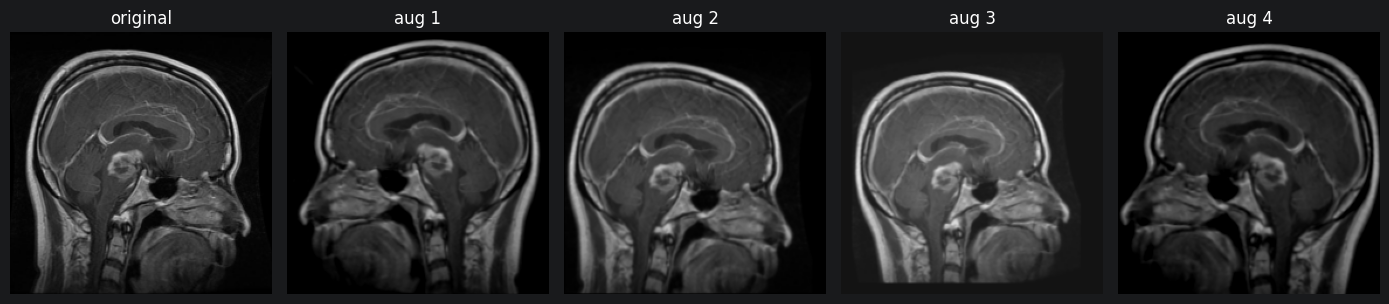

In [12]:
aug = build_augmenter(cfg.seed)
img = X_tr[:1].astype("float32")

plt.figure(figsize=(14, 3))
plt.subplot(1, 5, 1)
plt.imshow(X_tr[0][..., ::-1])
plt.title("original")
plt.axis("off")
for i in range(4):
    out = aug(img, training=True)[0].numpy().clip(0, 255).astype("uint8")
    plt.subplot(1, 5, i + 2)
    plt.imshow(out[..., ::-1])
    plt.title(f"aug {i + 1}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Build MobileNetV2

In [13]:
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = tf.keras.layers.Rescaling(2.0, offset=-1.0, name="to_minus1_1")(inputs)

base = tf.keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
)
base.trainable = False
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(cfg.dropout)(x)
outputs = tf.keras.layers.Dense(len(CLASSES), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="mobilenetv2_mri")
model.summary()

Model: "mobilenetv2_mri"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_minus1_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 8. Training helpers

In [14]:
from src.EpochTimer import EpochTimer


def make_callbacks(tag):
    timer = EpochTimer()
    return timer, [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
        tf.keras.callbacks.ModelCheckpoint(str(run_dir / f"best_{tag}.keras"), monitor="val_loss", save_best_only=True),
        tf.keras.callbacks.BackupAndRestore(backup_dir=str(run_dir / f"backup_{tag}")),
        timer,
    ]


def run_stage(tag, epochs, lr):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    timer, callbacks = make_callbacks(tag)
    t0 = time.perf_counter()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                  class_weight=class_weight, callbacks=callbacks)
    total = time.perf_counter() - t0
    print(f"\n[{tag}] {len(timer.times)} epochs | {total:.1f} s | mean/epoch {np.mean(timer.times):.1f} s")
    return {"history": h.history, "epoch_times_s": timer.times, "total_s": total}


stages = {}

## 9. Stage 1: train the head (backbone frozen)

In [15]:
stages["head"] = run_stage("head", cfg.head_epochs, cfg.learning_rate)

Epoch 1/10


I0000 00:00:1792583397.445289    4055 cuda_dnn.cc:529] Loaded cuDNN version 90300


145/145 ━━━━━━━━━━━━━━━━━━━━ 68s 439ms/step - accuracy: 0.6527 - loss: 0.8504 - val_accuracy: 0.7885 - val_loss: 0.5769 - learning_rate: 0.0010
Epoch 2/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 62s 428ms/step - accuracy: 0.8452 - loss: 0.4136 - val_accuracy: 0.8350 - val_loss: 0.4564 - learning_rate: 0.0010
Epoch 3/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 63s 431ms/step - accuracy: 0.8713 - loss: 0.3524 - val_accuracy: 0.7935 - val_loss: 0.5429 - learning_rate: 0.0010
Epoch 4/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 61s 422ms/step - accuracy: 0.8798 - loss: 0.3108 - val_accuracy: 0.8300 - val_loss: 0.4479 - learning_rate: 0.0010
Epoch 5/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 61s 423ms/step - accuracy: 0.8957 - loss: 0.2826 - val_accuracy: 0.8148 - val_loss: 0.4690 - learning_rate: 0.0010
Epoch 6/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 63s 435ms/step - accuracy: 0.9040 - loss: 0.2685 - val_accuracy: 0.8441 - val_loss: 0.4140 - learning_rate: 0.0010
Epoch 7/10
145/145 ━━━━━━━━━━━━━━━━━━━━ 62s 428ms/step - accuracy: 0.9038 - loss:

## 10. Stage 2: fine-tune the top backbone layers (low learning rate)

In [16]:
base.trainable = True
for layer in base.layers[:-cfg.finetune_layers]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
print("trainable backbone layers:", sum(l.trainable for l in base.layers), "of", len(base.layers))

stages["finetune"] = run_stage("finetune", cfg.finetune_epochs, cfg.finetune_lr)

# keep the best weights over BOTH stages (restore_best_weights only covers the last one)
best_tag = min(stages, key=lambda t: min(stages[t]["history"]["val_loss"]))
model = tf.keras.models.load_model(run_dir / f"best_{best_tag}.keras")
print("best stage by val loss:", best_tag)

(run_dir / "history.json").write_text(json.dumps(
    {"best_stage": best_tag, **stages}, indent=2, default=float,
))

trainable backbone layers: 19 of 154
Epoch 1/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 69s 449ms/step - accuracy: 0.9091 - loss: 0.2457 - val_accuracy: 0.8512 - val_loss: 0.4156 - learning_rate: 1.0000e-05
Epoch 2/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 64s 439ms/step - accuracy: 0.9278 - loss: 0.2031 - val_accuracy: 0.8927 - val_loss: 0.2983 - learning_rate: 1.0000e-05
Epoch 3/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 64s 440ms/step - accuracy: 0.9291 - loss: 0.1858 - val_accuracy: 0.8836 - val_loss: 0.3175 - learning_rate: 1.0000e-05
Epoch 4/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 64s 441ms/step - accuracy: 0.9329 - loss: 0.1769 - val_accuracy: 0.8978 - val_loss: 0.2978 - learning_rate: 1.0000e-05
Epoch 5/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 65s 444ms/step - accuracy: 0.9423 - loss: 0.1460 - val_accuracy: 0.8957 - val_loss: 0.2913 - learning_rate: 1.0000e-05
Epoch 6/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 64s 438ms/step - accuracy: 0.9466 - loss: 0.1403 - val_accuracy: 0.8856 - val_loss: 0.2931 - learning_rate: 1.0000e-05
Epoch 7/1

4403

## 11. Training curves and fit analysis

In [1]:
head_h, ft_h = stages["head"]["history"], stages["finetune"]["history"]
h = {k: head_h[k] + ft_h[k] for k in head_h if k in ft_h}
n_head = len(head_h["loss"])
epochs = np.arange(1, len(h["loss"]) + 1)
best = int(np.argmin(h["val_loss"]))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, m in zip(ax, ("loss", "accuracy")):
    a.plot(epochs, h[m], label="train")
    a.plot(epochs, h[f"val_{m}"], label="validation")
    a.axvline(n_head + 0.5, color="gray", linestyle="--", label="fine-tuning starts")
    a.set_title(m)
    a.set_xlabel("epoch")
    a.legend()
plt.tight_layout()
plt.show()

tr_acc, va_acc = h["accuracy"][best], h["val_accuracy"][best]
tr_loss, va_loss = h["loss"][best], h["val_loss"][best]
acc_gap = tr_acc - va_acc
loss_gap = va_loss - tr_loss

print(f"best epoch: {best + 1} of {len(epochs)} ({'head' if best < n_head else 'finetune'} stage)")
print(f"train acc  {tr_acc:.3f} | val acc  {va_acc:.3f} | gap {acc_gap:+.3f}")
print(f"train loss {tr_loss:.3f} | val loss {va_loss:.3f} | gap {loss_gap:+.3f}")

if acc_gap > 0.10:
    verdict = "OVERFITTING: train accuracy is far above validation accuracy"
elif acc_gap > 0.05:
    verdict = "mild overfitting"
elif tr_acc < 0.85 and va_acc < 0.85:
    verdict = "possible UNDERFITTING: both accuracies are low, train longer or unfreeze more layers"
else:
    verdict = "good fit: small gap between train and validation"
print("verdict:", verdict)

NameError: name 'stages' is not defined

## 12. Evaluate on validation

In [ ]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"val loss: {val_loss:.4f} | val accuracy: {val_acc:.4f}")

## 13. Per-class report
`val_ds` is not shuffled, so predictions and labels line up. Predictions are computed once and reused below.

In [ ]:
xs, ys = [], []
for xb, yb in val_ds:
    xs.append(xb.numpy())
    ys.append(yb.numpy())
X_val_img = np.concatenate(xs)
y_true = np.concatenate(ys)

probs = model.predict(X_val_img, batch_size=BATCH_SIZE, verbose=0)
y_pred = probs.argmax(axis=1)
conf = probs.max(axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(
    confusion_matrix(y_true, y_pred), display_labels=CLASSES
).plot(cmap="Blues", xticks_rotation=45)
plt.show()

## 14. Confusion analysis (validation only; the test set stays untouched)

In [ ]:
wrong = np.where(y_pred != y_true)[0]
right = np.where(y_pred == y_true)[0]

print(f"{len(wrong)} misclassified of {len(y_true)} ({100 * len(wrong) / len(y_true):.1f}%)")
if len(wrong):
    print(f"mean confidence: correct {conf[right].mean():.3f} | wrong {conf[wrong].mean():.3f}")
    print(f"wrong predictions with confidence > 0.9: {(conf[wrong] > 0.9).sum()} of {len(wrong)}")

labels = list(range(len(CLASSES)))
cm = confusion_matrix(y_true, y_pred, labels=labels)
pairs = sorted(((cm[i, j], i, j) for i in labels for j in labels if i != j and cm[i, j] > 0), reverse=True)

print("\nMost frequent confusions (true -> predicted):")
for n, i, j in pairs[:6]:
    print(f"  {CLASSES[i]:>11} -> {CLASSES[j]:<11} {n:>4}  ({100 * n / cm[i].sum():.1f}% of all true {CLASSES[i]})")

missed = sum(cm[i, CLASSES.index("notumor")] for i in labels if CLASSES[i] != "notumor")
print(f"\ntumor predicted as 'notumor' (missed tumors): {missed}")


def show(idx, title, cols=5, max_n=10):
    idx = list(idx)[:max_n]
    if not idx:
        print(f"{title}: none")
        return
    rows = int(np.ceil(len(idx) / cols))
    plt.figure(figsize=(3 * cols, 3.3 * rows))
    for k, i in enumerate(idx):
        plt.subplot(rows, cols, k + 1)
        plt.imshow(X_val_img[i][..., ::-1])
        ok = y_true[i] == y_pred[i]
        plt.title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]} ({conf[i]:.2f})",
                  fontsize=9, color="green" if ok else "red")
        plt.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


show(wrong[np.argsort(-conf[wrong])], "Most confident mistakes")

for n, i, j in pairs[:3]:
    idx = np.where((y_true == i) & (y_pred == j))[0]
    show(idx[np.argsort(-conf[idx])], f"True {CLASSES[i]} predicted as {CLASSES[j]} ({n} images)", max_n=5)

for c in labels:
    idx = right[y_true[right] == c]
    show(idx[np.argsort(-conf[idx])], f"Correct {CLASSES[c]} (reference)", max_n=5)

## 15 Save model

In [ ]:
model_path = run_dir / "model.keras"
model.save(model_path)
print(f"Saved to: {model_path.resolve()}")

after open the terminal and run
```scp -P YOUR_PORT root@YOUR_SERVER_IP:/workspace/runs/model.keras "$HOME\Desktop\model.keras"```

## 16. Final test (run once)

In [ ]:
if "test_result" not in globals():
    test_ds = get_test_ds(spec, BATCH_SIZE)
    test_loss, test_acc = model.evaluate(test_ds)
    test_result = {
        "loss": float(test_loss),
        "accuracy": float(test_acc),
        "y_true": np.concatenate([yb.numpy() for _, yb in test_ds]),
        "y_pred": np.argmax(model.predict(test_ds, verbose=0), axis=1),
    }
    (run_dir / "test_result.json").write_text(
        json.dumps({"loss": test_result["loss"], "accuracy": test_result["accuracy"]}, indent=2)
    )
else:
    print("Test set already evaluated: showing the stored result, not evaluating again.")

print(f"TEST loss: {test_result['loss']:.4f} | TEST accuracy: {test_result['accuracy']:.4f}")
print(classification_report(test_result["y_true"], test_result["y_pred"], target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(
    confusion_matrix(test_result["y_true"], test_result["y_pred"]), display_labels=CLASSES
).plot(cmap="Blues", xticks_rotation=45)
plt.show()

## 17. Predict one image

In [ ]:
import importlib
import src.predict as sp
importlib.reload(sp)
from src.predict import predict_image, show_prediction

sample_dir = Path(RAW_DIR) / CLASSES[0]
sample = sorted(p for p in sample_dir.iterdir() if p.is_file())[0]
print(sample)

result = predict_image(sample, model, CLASSES)
print({k: v for k, v in result.items() if k != "image"})
show_prediction(result)